<font size="+3">Monitor : BindCraft Designs in Funnel Metadynamics  </font>


In [7]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import shutil
import glob

from pandas.api.types import CategoricalDtype
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score
import matplotlib.transforms as mtransforms

In [3]:
def plot_adjust_settings(xlabel, ylabel, ax=None):
    if ax is None:
        ax = plt.gca()
        
    ax.set_xlabel(xlabel,fontsize=11,labelpad=7)
    ax.set_ylabel(ylabel,fontsize=11,labelpad=7)
    ax.tick_params(labelsize=9, pad=5)
    

# Binding Free Energy

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_46861/572576355.py:18: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='Experimental', ax=ax,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_46861/572576355.py:18: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='Experimental', ax=ax,


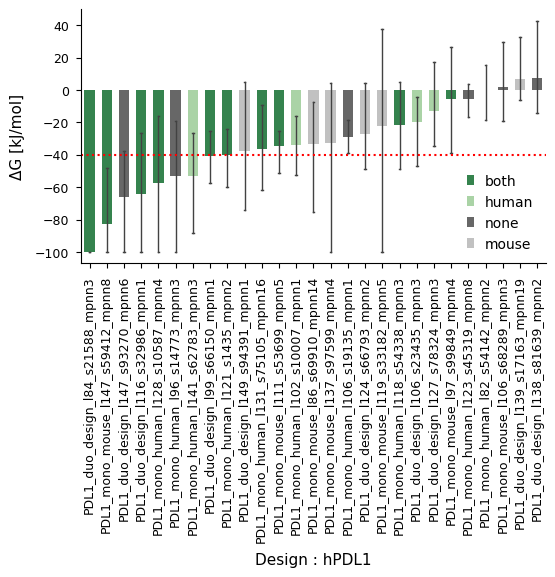

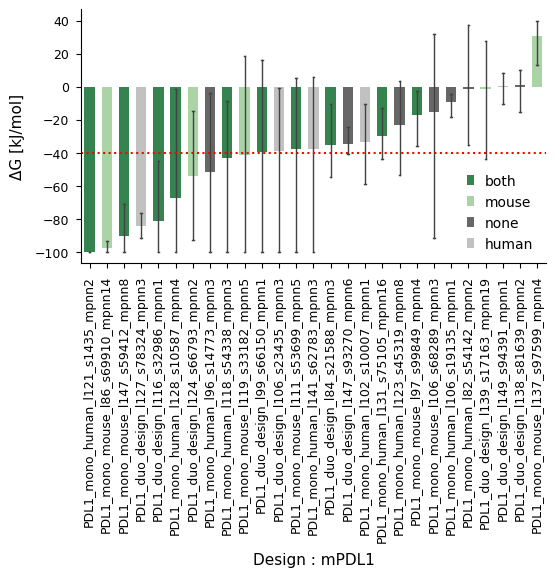

In [4]:
pal = ['#289049', '#a4da9e', '#676767', '#c1c1c1']
df_all = pd.read_pickle('deltaG_labled.pkl')
df_all = df_all[df_all['Experimental'] != 'unknown' ]

for name, df in df_all.groupby('target'):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.3))
    
    if name == 'human':
        exp_order = CategoricalDtype(['both', 'human', 'none', 'mouse'], ordered=True)
    else:
        exp_order = CategoricalDtype(['both', 'mouse', 'none', 'human'], ordered=True)
    df['Experimental'] = df['Experimental'].astype(exp_order)

    df_avg = df.groupby(['Design', 'batch'], as_index=False)['deltaG'].mean()
    df_best = df_avg.groupby('Design')['deltaG'].min().sort_values()
    order = df_best.index.tolist()

    sns.barplot(df, x='Design', y='deltaG', hue='Experimental', ax=ax,
                errwidth=1, capsize=0.1, width=0.6, order=order, palette=pal)

    plot_adjust_settings(f'Design : {name[0]}PDL1', 'ΔG [kJ/mol]')
    ax.legend(frameon=False, title='', handlelength=0.5, loc='lower right')
    ax.tick_params(axis='x', rotation=90)
    sns.despine()
    ax.axhline(-40, color='red', linestyle=':')
    #ax.set_ylim(-130, 10)

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/4092869643.py:23: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='binary', ax=ax,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/4092869643.py:23: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.barplot(df, x='Design', y='deltaG', hue='binary', ax=ax,


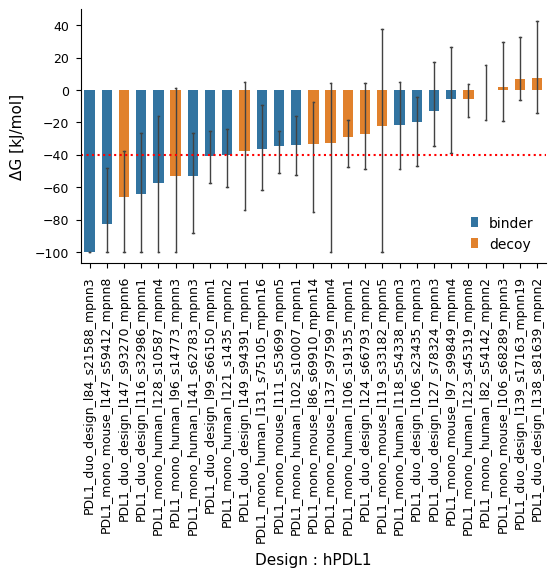

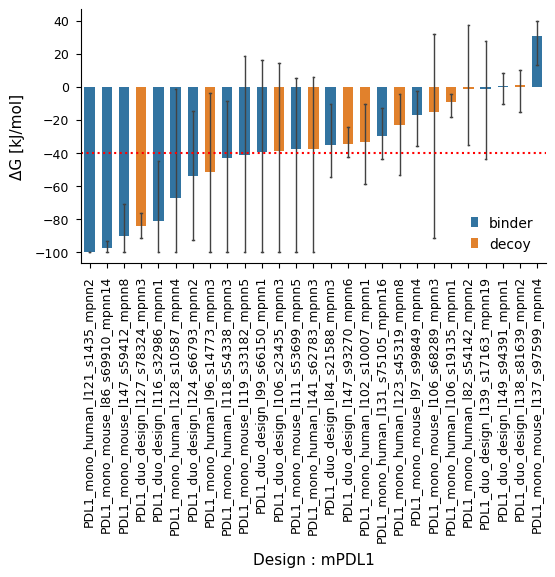

In [5]:
df_all = pd.read_pickle('deltaG_labled.pkl')
df_all = df_all[df_all['Experimental'] != 'unknown' ]

df_all['binary'] = np.select(
    [
        df_all['Experimental'].eq('none'),            # rule 1
        df_all['Experimental'].eq('both'),            # rule 2
        df_all['Experimental'].eq(df_all['target'])       # rule 3
    ],
    ['decoy', 'binder', 'binder'],
    default='decoy'
)


for name, df in df_all.groupby('target'):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.3))
    
    df = df.sort_values(by = 'binary')
    df_avg = df.groupby(['Design', 'batch'], as_index=False)['deltaG'].mean()
    df_best = df_avg.groupby('Design')['deltaG'].min().sort_values()
    order = df_best.index.tolist()

    sns.barplot(df, x='Design', y='deltaG', hue='binary', ax=ax,
                errwidth=1, capsize=0.1, width=0.6, order=order)

    plot_adjust_settings(f'Design : {name[0]}PDL1', 'ΔG [kJ/mol]')
    ax.legend(frameon=False, title='', handlelength=0.5, loc='lower right')
    ax.tick_params(axis='x', rotation=90)
    sns.despine()
    ax.axhline(-40, color='red', linestyle=':')
    #ax.set_ylim(-130, 10)
    

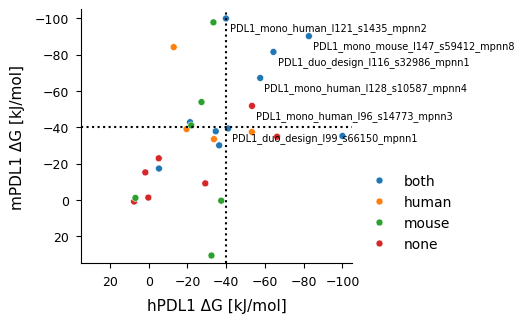

In [6]:
pal = ['#289049', '#a4da9e', '#676767', '#c1c1c1']
df = pd.read_pickle('deltaG_labled.pkl')
df = df_all[df_all['Experimental'] != 'unknown' ]

# per binder (averaged over replicas)
agg = (df.groupby(['Design', 'target', 'Experimental'])
         .agg(mean_deltaG=('deltaG','mean'),
              std_deltaG=('deltaG','std'))
         .reset_index())

lst=[]
for name, df in agg.groupby('target'):
    df = df.rename(columns={
        'mean_deltaG': f'{name}_mean_deltaG',
        'std_deltaG':  f'{name}_std_deltaG'
    })
    df = df.drop(columns=['target'])
    lst.append(df)

df = pd.merge(lst[0], lst[1], on=['Design', 'Experimental'])
exp_order = CategoricalDtype(['both', 'human', 'mouse', 'none'], ordered=True)
df['Experimental'] = df['Experimental'].astype(exp_order)
# plot
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.3))
sns.scatterplot(df, x='human_mean_deltaG', y='mouse_mean_deltaG', hue='Experimental', ax=ax, s=25)

plot_adjust_settings('hPDL1 ΔG [kJ/mol]', 'mPDL1 ΔG [kJ/mol]')
ax.legend(bbox_to_anchor=(1,0.4), frameon=False, loc='upper left')
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(35, -105)
ax.set_ylim(35, -105)
sns.despine()
ax.axhline(-40, color='black', linestyle=':')
ax.axvline(-40, color='black', linestyle=':')

# labels
mask = (df['human_mean_deltaG'] < -39) & (df['mouse_mean_deltaG'] < -39)
for _, r in df[mask].iterrows():
    ax.annotate(r['Design'],
                (r['human_mean_deltaG'], r['mouse_mean_deltaG']),
                textcoords='offset points', xytext=(3, -3), ha='left', va='top',
                fontsize=7)

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/1415223938.py:39: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: average_precision_score(g['y'], g['score']))


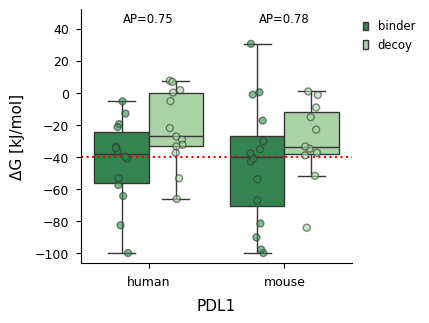

In [11]:
pal = ['#289049', '#a4da9e']
df = pd.read_pickle('deltaG_labled.pkl')
df = df[df['Experimental'] != 'unknown' ]

# per binder (averaged over replicas)
df = (df.groupby(['Design', 'target', 'Experimental'])
         .agg(deltaG=('deltaG','mean'))
         .reset_index())

df['binary'] = np.select(
    [
        df['Experimental'].eq('none'),            # rule 1
        df['Experimental'].eq('both'),            # rule 2
        df['Experimental'].eq(df['target'])       # rule 3
    ],
    ['decoy', 'binder', 'binder'],
    default='decoy'
)

# plot
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.3))
sns.boxplot(df, x='target', y='deltaG', hue='binary', ax=ax, showfliers=False, palette=pal)
sns.stripplot(df, x='target', y='deltaG', hue='binary', dodge=True,
              jitter=True, alpha=0.6, marker='o', linewidth=1, palette=pal)

plot_adjust_settings('PDL1', 'ΔG [kJ/mol]')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[:2], labels=labels[:2], frameon=False, title='', handlelength=0.5, fontsize='small', loc='upper left', bbox_to_anchor=(1,1))
ax.axhline(-40, color='red', linestyle=':')
sns.despine()

# average precision
from sklearn.metrics import average_precision_score

# compute AP per target (binder=positive), lower ΔG -> higher score
ap_by_target = (df.assign(y=(df['binary'] == 'binder').astype(int),
                          score=-df['deltaG'])
                  .groupby('target')
                  .apply(lambda g: average_precision_score(g['y'], g['score']))
                  .to_dict())

# after plotting:
ymax = ax.get_ylim()[1]
ax.set_ylim(ax.get_ylim()[0], ymax + 15)  # headroom
for x, lbl in zip(ax.get_xticks(), [t.get_text() for t in ax.get_xticklabels()]):
    if lbl in ap_by_target:
        ax.text(x, ymax + 5, f"AP={ap_by_target[lbl]:.2f}",
                ha='center', va='bottom', fontsize='small')

0.5925925925925926


/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/1672758224.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: average_precision_score(g['y'], g['score']))


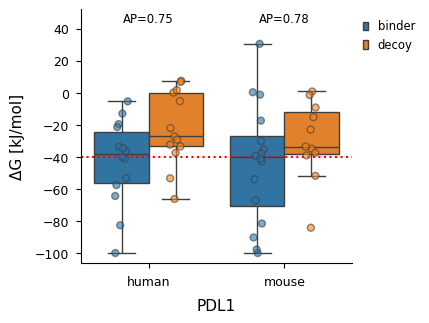

In [12]:
pal = ['#289049', '#a4da9e']
df = pd.read_pickle('deltaG_labled.pkl')
df = df[df['Experimental'] != 'unknown' ]

# per binder (averaged over replicas)
df = (df.groupby(['Design', 'target', 'Experimental'])
         .agg(deltaG=('deltaG','mean'))
         .reset_index())

df['binary'] = np.select(
    [
        df['Experimental'].eq('none'),            # rule 1
        df['Experimental'].eq('both'),            # rule 2
        df['Experimental'].eq(df['target'])       # rule 3
    ],
    ['decoy', 'binder', 'binder'],
    default='decoy'
)

tmp = df[df['target'] == 'mouse']
binders = tmp[tmp['binary'] == 'binder']
print(len(binders)/len(tmp))

# plot
fig, ax = plt.subplots(1, 1, figsize=(3.5, 3.3))
sns.boxplot(df, x='target', y='deltaG', hue='binary', ax=ax, showfliers=False)
sns.stripplot(df, x='target', y='deltaG', hue='binary', dodge=True,
              jitter=True, alpha=0.6, marker='o', linewidth=1)

plot_adjust_settings('PDL1', 'ΔG [kJ/mol]')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles[:2], labels=labels[:2], frameon=False, title='', handlelength=0.5, fontsize='small', loc='upper left', bbox_to_anchor=(1,1))
ax.axhline(-40, color='red', linestyle=':')
sns.despine()

# average precision
from sklearn.metrics import average_precision_score

# compute AP per target (binder=positive), lower ΔG -> higher score
ap_by_target = (df.assign(y=(df['binary'] == 'binder').astype(int),
                          score=-df['deltaG'])
                  .groupby('target')
                  .apply(lambda g: average_precision_score(g['y'], g['score']))
                  .to_dict())

# after plotting:
ymax = ax.get_ylim()[1]
ax.set_ylim(ax.get_ylim()[0], ymax + 15)  # headroom
for x, lbl in zip(ax.get_xticks(), [t.get_text() for t in ax.get_xticklabels()]):
    if lbl in ap_by_target:
        ax.text(x, ymax + 5, f"AP={ap_by_target[lbl]:.2f}",
                ha='center', va='bottom', fontsize='small')

# Reprediction

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_46861/678402290.py:81: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(auc_score)
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_46861/678402290.py:81: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(auc_score)
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_46861/678402290.py:81: DeprecationWarning: DataFrameGroupBy

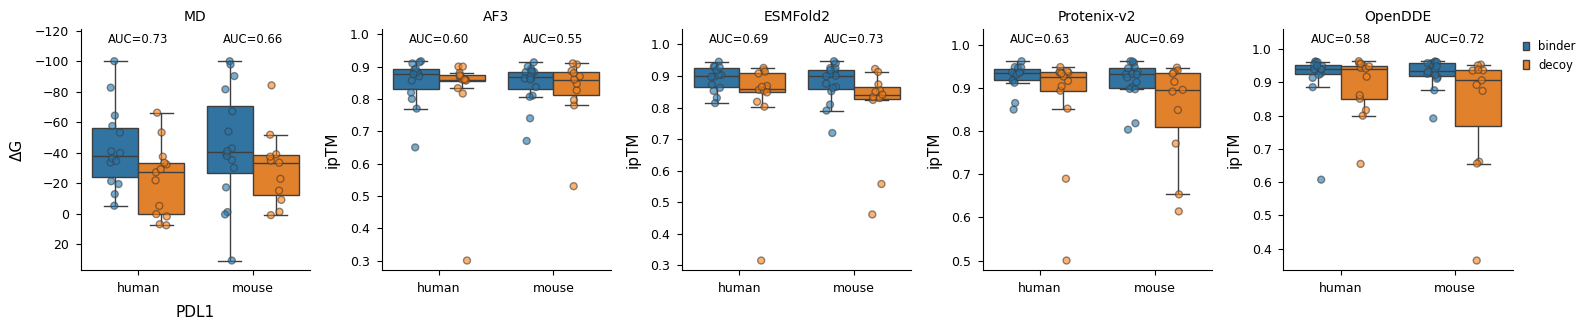

In [5]:
anno = pd.read_csv('experimental_labels.csv')

def add_binary(df):
    """Attach experimental annotation + binder/decoy label (drops 'unknown')."""
    df = pd.merge(df, anno, how='left', on='Design')
    df = df[df['Experimental'] != 'unknown'].copy()
    df['binary'] = np.select(
        [
            df['Experimental'].eq('none'),          # rule 1
            df['Experimental'].eq('both'),          # rule 2
            df['Experimental'].eq(df['target']),    # rule 3
        ],
        ['decoy', 'binder', 'binder'],
        default='decoy',
    )
    return df

# ---- MD: deltaG (averaged over replicas), lower = better -----------------
md = pd.read_pickle('deltaG_labled.pkl')
md = md[md['Experimental'] != 'unknown']
md = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
        .agg(deltaG=('deltaG', 'mean')))
md['binary'] = np.select(
    [md['Experimental'].eq('none'),
     md['Experimental'].eq('both'),
     md['Experimental'].eq(md['target'])],
    ['decoy', 'binder', 'binder'], default='decoy')

# ---- Predictors: iptm (long form over both targets), higher = better -----
def load_iptm(folder):
    h = pd.read_csv(f'{folder}/hPDL1/output.csv')[['ID', 'iptm']].assign(target='human')
    m = pd.read_csv(f'{folder}/mPDL1/output.csv')[['ID', 'iptm']].assign(target='mouse')
    df = pd.concat([h, m]).rename(columns={'ID': 'Design'})
    # average over the 3 seeds -> one value per (Design, target)
    df = (df.groupby(['Design', 'target'], as_index=False)
            .agg(iptm=('iptm', 'mean'),
                 iptm_sd=('iptm', 'std'),
                 n_seeds=('iptm', 'size')))
    return add_binary(df)

# panel spec: (dataframe, value column, ylabel, higher_is_better, invert_y, title)
panels = [
    (md,                                 'deltaG', 'ΔG',   False, True,  'MD'),
    (load_iptm('AF3_repredict'),         'iptm',   'ipTM', True,  False, 'AF3'),
    (load_iptm('ESMFold2_repredict'),    'iptm',   'ipTM', True,  False, 'ESMFold2'),
    (load_iptm('Protenix-v2_repredict'), 'iptm',   'ipTM', True,  False, 'Protenix-v2'),
    (load_iptm('OpenDDE_repredict'),     'iptm',   'ipTM', True,  False, 'OpenDDE'),
]

def auc_score(g):
    """ROC-AUC; NaN if single-class."""
    y = (g['binary'] == 'binder').astype(int)
    if y.nunique() < 2:
        return np.nan
    return roc_auc_score(y, g['score'])

fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))

for i, (ax, (df, ycol, ylabel, higher_better, invert_y, title)) in enumerate(zip(axes, panels)):
    sns.boxplot(df, x='target', y=ycol, hue='binary', ax=ax, showfliers=False)
    sns.stripplot(df, x='target', y=ycol, hue='binary', dodge=True,
                  jitter=True, alpha=0.6, marker='o', linewidth=1, ax=ax)

    xlabel = 'PDL1' if i == 0 else ''
    plot_adjust_settings(xlabel, ylabel, ax=ax)
    ax.set_title(title, fontsize=10)

    # legend only on the last panel, to the right
    if i == len(panels) - 1:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles=handles[:2], labels=labels[:2], frameon=False, title='',
                  handlelength=0.5, fontsize='small', loc='upper left', bbox_to_anchor=(1, 1))
    else:
        ax.legend_.remove()

    # AUC per target (binder = positive)
    # score orientation: higher score -> more binder-like
    score = df[ycol] if higher_better else -df[ycol]
    auc_by_target = (df.assign(score=score)
                       .groupby('target')
                       .apply(auc_score)
                       .to_dict())

    if invert_y:
        ax.invert_yaxis()                       # more negative (good) on top
        ylo, yhi = ax.get_ylim()                # ylo > yhi (inverted)
        pad = 0.10 * (ylo - yhi)
        ax.set_ylim(ylo, yhi - pad)
        ytext = yhi - 0.25 * pad
    else:
        ymin, ymax = ax.get_ylim()
        pad = 0.10 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + pad)
        ytext = ymax + 0.25 * pad

    for x, lbl in zip(ax.get_xticks(), [t.get_text() for t in ax.get_xticklabels()]):
        if lbl in auc_by_target and np.isfinite(auc_by_target[lbl]):
            ax.text(x, ytext, f"AUC={auc_by_target[lbl]:.2f}",
                    ha='center', va='bottom', fontsize='small')

sns.despine(fig=fig)
fig.tight_layout()

,method,AUC,lo,hi
0,MD,0.694,0.512,0.849
1,AF3,0.581,0.417,0.742
2,ESMFold2,0.708,0.565,0.840
3,Protenix-v2,0.656,0.494,0.797
4,OpenDDE,0.647,0.492,0.786


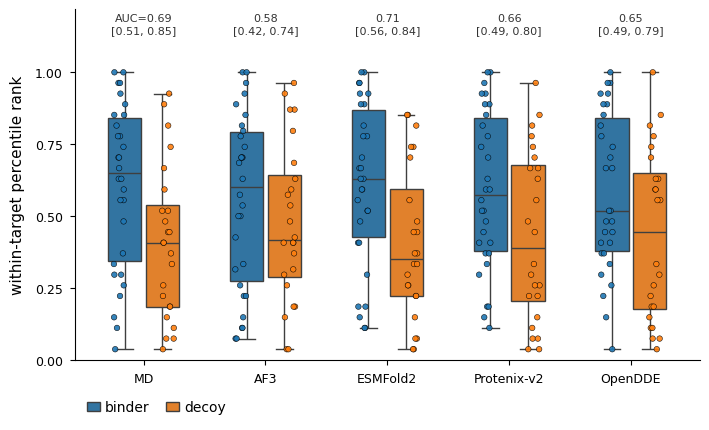

In [8]:
# ---- pooled campaign panel: within-target percentile rank ----------------
METHODS = ["MD", "AF3", "ESMFold2", "Protenix-v2", "OpenDDE"]
FOLDER  = {"AF3": "AF3_repredict", "ESMFold2": "ESMFold2_repredict",
           "Protenix-v2": "Protenix-v2_repredict", "OpenDDE": "OpenDDE_repredict"}
N_BOOT, SEED = 4000, 0

anno = pd.read_csv('experimental_labels.csv')

def add_binary(df):
    df = pd.merge(df, anno, how='left', on='Design')
    df = df[df['Experimental'] != 'unknown'].copy()
    df['binary'] = np.select(
        [df['Experimental'].eq('none'),
         df['Experimental'].eq('both'),
         df['Experimental'].eq(df['target'])],
        ['decoy', 'binder', 'binder'], default='decoy')
    return df

# MD: ΔG averaged over replicas, lower = better, so score = -ΔG
md = pd.read_pickle('deltaG_labled.pkl')
md = md[md['Experimental'] != 'unknown']
md = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
        .agg(deltaG=('deltaG', 'mean')))
md['binary'] = np.select(
    [md['Experimental'].eq('none'),
     md['Experimental'].eq('both'),
     md['Experimental'].eq(md['target'])],
    ['decoy', 'binder', 'binder'], default='decoy')
md = md.assign(method='MD', score=-md['deltaG'])

# predictors: ipTM averaged over the 3 seeds, higher = better
def load_iptm(folder, name):
    h = pd.read_csv(f'{folder}/hPDL1/output.csv')[['ID', 'iptm']].assign(target='human')
    m = pd.read_csv(f'{folder}/mPDL1/output.csv')[['ID', 'iptm']].assign(target='mouse')
    df = (pd.concat([h, m]).rename(columns={'ID': 'Design'})
            .groupby(['Design', 'target'], as_index=False).agg(iptm=('iptm', 'mean')))
    return add_binary(df).assign(method=name, score=lambda d: d['iptm'])

cols = ['Design', 'target', 'Experimental', 'binary', 'method', 'score']
long = pd.concat([md[cols]] + [load_iptm(FOLDER[m], m)[cols] for m in METHODS[1:]],
                 ignore_index=True)
long['y']    = (long.binary == 'binder').astype(int)
long['rank'] = long.groupby(['method', 'target'])['score'].rank(pct=True)

def rank_auc(g):
    """AUC on within-target percentile ranks, recomputed for whatever rows are passed."""
    return roc_auc_score(g.y, g.groupby('target')['score'].rank(pct=True))

def rank_auc_ci(g, n_boot=N_BOOT, seed=SEED):
    """Percentile bootstrap resampling DESIGNS, since each appears in both targets."""
    rng = np.random.default_rng(seed)
    designs   = g.Design.unique()
    by_design = {d: sub for d, sub in g.groupby('Design')}
    v = []
    for _ in range(n_boot):
        pick = rng.choice(designs, size=len(designs), replace=True)
        b = pd.concat([by_design[d] for d in pick])
        if b.y.nunique() < 2:
            continue
        v.append(rank_auc(b))
    return np.percentile(v, [2.5, 97.5])

stats = pd.DataFrame([
    dict(method=m, AUC=rank_auc(long[long.method == m]),
         **dict(zip(['lo', 'hi'], rank_auc_ci(long[long.method == m]))))
    for m in METHODS])
display(stats.round(3))

kw = dict(x='method', y='rank', hue='binary', order=METHODS,
          hue_order=['binder', 'decoy'], dodge=True)

fig, ax = plt.subplots(figsize=(7.2, 4.4))
sns.boxplot(long, **kw, showfliers=False, width=0.62, gap=0.12, ax=ax)
sns.stripplot(long, **kw, size=4, edgecolor='black', linewidth=0.4,
              alpha=0.9, ax=ax, legend=False)

ax.set_ylim(0, 1.22)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])

trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
for i, r in stats.iterrows():
    txt = (f"AUC={r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]" if i == 0
           else f"{r.AUC:.2f}\n[{r.lo:.2f}, {r.hi:.2f}]")
    ax.text(i, 0.99, txt, transform=trans, ha='center', va='top',
            fontsize=8, linespacing=1.3, color='#333333')

plot_adjust_settings('', 'within-target percentile rank', ax=ax)
ax.margins(x=0.06)

h, l = ax.get_legend_handles_labels()
ax.legend(h[:2], l[:2], loc='upper left', bbox_to_anchor=(0.0, -0.08), ncol=2,
          frameon=False, handlelength=0.9, handletextpad=0.4, columnspacing=1.2)

sns.despine(fig)
fig.tight_layout()

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/1823694339.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/1823694339.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/1823694339.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/var/

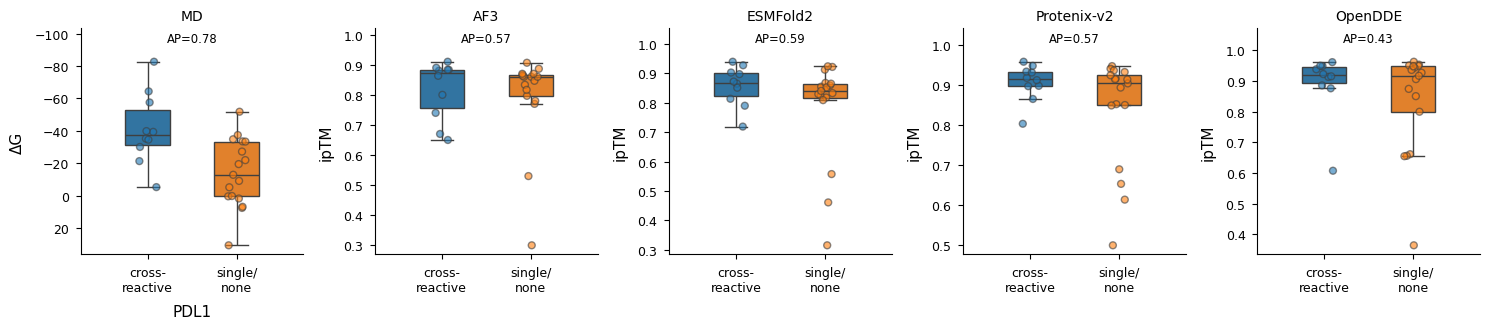

In [18]:
anno = pd.read_csv('experimental_labels.csv')
order = ['cross-reactive', 'single/none']
pal = {'cross-reactive': '#1f77b4', 'single/none': '#ff7f0e'}

def add_group(df):
    df = pd.merge(df, anno, how='left', on='Design')
    df = df[df['Experimental'] != 'unknown'].copy()
    df['group'] = np.where(df['Experimental'].eq('both'), 'cross-reactive', 'single/none')
    return df

# ---- MD: worst-target ΔG (averaged over replicas), lower = better ---------
md = pd.read_pickle('deltaG_labled.pkl')
md = md[md['Experimental'] != 'unknown']
agg = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
         .agg(mean_deltaG=('deltaG', 'mean')))
lst = []
for name, g in agg.groupby('target'):
    lst.append(g.rename(columns={'mean_deltaG': f'{name}_mean_deltaG'}).drop(columns=['target']))
md = pd.merge(lst[0], lst[1], on=['Design', 'Experimental'])
md['group'] = np.where(md['Experimental'].eq('both'), 'cross-reactive', 'single/none')
md['value'] = md[['human_mean_deltaG', 'mouse_mean_deltaG']].max(axis=1)  # bottleneck target

# ---- Predictors: worst-target iptm (wide over targets), higher = better ---
def load_iptm_min(folder):
    def one(target):
        d = pd.read_csv(f'{folder}/{target}/output.csv')[['ID', 'iptm']]
        # average over the 3 seeds BEFORE the merge, else h x m cross product
        return d.groupby('ID', as_index=False)['iptm'].mean()
    h, m = one('hPDL1'), one('mPDL1')
    df = pd.merge(h, m, on='ID', suffixes=('_h', '_m')).rename(columns={'ID': 'Design'})
    df = add_group(df)
    df['value'] = df[['iptm_h', 'iptm_m']].min(axis=1)  # bottleneck target
    return df

# panel spec: (dataframe, ylabel, higher_is_better, invert_y, title)
panels = [
    (md,                                     'ΔG',   False, True,  'MD'),
    (load_iptm_min('AF3_repredict'),         'ipTM', True,  False, 'AF3'),
    (load_iptm_min('ESMFold2_repredict'),    'ipTM', True,  False, 'ESMFold2'),
    (load_iptm_min('Protenix-v2_repredict'), 'ipTM', True,  False, 'Protenix-v2'),
    (load_iptm_min('OpenDDE_repredict'),     'ipTM', True,  False, 'OpenDDE'),
]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))

for i, (ax, (df, ylabel, higher_better, invert_y, title)) in enumerate(zip(axes, panels)):
    sns.boxplot(df, x='group', y='value', order=order, palette=pal,
                width=0.5, showfliers=False, ax=ax)
    sns.stripplot(df, x='group', y='value', order=order, palette=pal,
                  jitter=True, alpha=0.6, marker='o', linewidth=1, ax=ax)

    xlabel = 'PDL1' if i == 0 else ''
    plot_adjust_settings(xlabel, ylabel, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([g.replace('-', '-\n').replace('/', '/\n') for g in order])

    # average precision (cross-reactive = positive)
    score = df['value'] if higher_better else -df['value']
    ap = average_precision_score((df['group'] == 'cross-reactive').astype(int), score)

    if invert_y:
        ax.invert_yaxis()                       # more negative (better) on top
        ylo, yhi = ax.get_ylim()                # ylo > yhi (inverted)
        pad = 0.12 * (ylo - yhi)
        ax.set_ylim(ylo, yhi - pad)
        ax.text(0.5, yhi - 0.3 * pad, f"AP={ap:.2f}", ha='center', va='bottom', fontsize='small')
    else:
        ymin, ymax = ax.get_ylim()
        pad = 0.12 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + pad)
        ax.text(0.5, ymax + 0.3 * pad, f"AP={ap:.2f}", ha='center', va='bottom', fontsize='small')

sns.despine(fig=fig)
fig.tight_layout()

/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/344181016.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/344181016.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(df, x='group', y='value', order=order, palette=pal,
/var/folders/mg/jhh2rvf11vd1jd013_6qqg200000gn/T/ipykernel_8026/344181016.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(df, x='group', y='value', order=order, palette=pal,
/var/fol

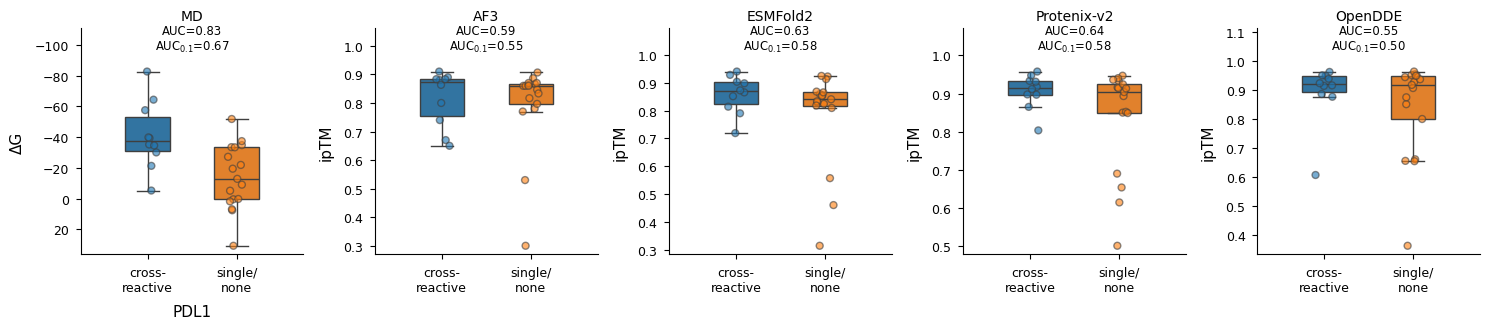

In [19]:
anno = pd.read_csv('experimental_labels.csv')
order = ['cross-reactive', 'single/none']
pal = {'cross-reactive': '#1f77b4', 'single/none': '#ff7f0e'}

def add_group(df):
    df = pd.merge(df, anno, how='left', on='Design')
    df = df[df['Experimental'] != 'unknown'].copy()
    df['group'] = np.where(df['Experimental'].eq('both'), 'cross-reactive', 'single/none')
    return df

# ---- MD: worst-target ΔG (averaged over replicas), lower = better ---------
md = pd.read_pickle('deltaG_labled.pkl')
md = md[md['Experimental'] != 'unknown']
agg = (md.groupby(['Design', 'target', 'Experimental'], as_index=False)
         .agg(mean_deltaG=('deltaG', 'mean')))
lst = []
for name, g in agg.groupby('target'):
    lst.append(g.rename(columns={'mean_deltaG': f'{name}_mean_deltaG'}).drop(columns=['target']))
md = pd.merge(lst[0], lst[1], on=['Design', 'Experimental'])
md['group'] = np.where(md['Experimental'].eq('both'), 'cross-reactive', 'single/none')
md['value'] = md[['human_mean_deltaG', 'mouse_mean_deltaG']].max(axis=1)  # bottleneck target

# ---- Predictors: worst-target iptm (wide over targets), higher = better ---
def load_iptm_min(folder):
    def one(target):
        d = pd.read_csv(f'{folder}/{target}/output.csv')[['ID', 'iptm']]
        # average over the 3 seeds BEFORE the merge, else h x m cross product
        return d.groupby('ID', as_index=False)['iptm'].mean()
    h, m = one('hPDL1'), one('mPDL1')
    df = pd.merge(h, m, on='ID', suffixes=('_h', '_m')).rename(columns={'ID': 'Design'})
    df = add_group(df)
    df['value'] = df[['iptm_h', 'iptm_m']].min(axis=1)  # bottleneck target
    return df

# panel spec: (dataframe, ylabel, higher_is_better, invert_y, title)
panels = [
    (md,                                     'ΔG',   False, True,  'MD'),
    (load_iptm_min('AF3_repredict'),         'ipTM', True,  False, 'AF3'),
    (load_iptm_min('ESMFold2_repredict'),    'ipTM', True,  False, 'ESMFold2'),
    (load_iptm_min('Protenix-v2_repredict'), 'ipTM', True,  False, 'Protenix-v2'),
    (load_iptm_min('OpenDDE_repredict'),     'ipTM', True,  False, 'OpenDDE'),
]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))

for i, (ax, (df, ylabel, higher_better, invert_y, title)) in enumerate(zip(axes, panels)):
    sns.boxplot(df, x='group', y='value', order=order, palette=pal,
                width=0.5, showfliers=False, ax=ax)
    sns.stripplot(df, x='group', y='value', order=order, palette=pal,
                  jitter=True, alpha=0.6, marker='o', linewidth=1, ax=ax)

    xlabel = 'PDL1' if i == 0 else ''
    plot_adjust_settings(xlabel, ylabel, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([g.replace('-', '-\n').replace('/', '/\n') for g in order])

    # AUC + standardized partial AUC (FPR<=0.1); cross-reactive = positive
    score = df['value'] if higher_better else -df['value']
    y = (df['group'] == 'cross-reactive').astype(int)
    if y.nunique() < 2:
        auc = auc01 = np.nan
    else:
        auc = roc_auc_score(y, score)
        auc01 = roc_auc_score(y, score, max_fpr=0.1)
    txt = f"AUC={auc:.2f}\nAUC$_{{0.1}}$={auc01:.2f}"

    if invert_y:
        ax.invert_yaxis()                       # more negative (better) on top
        ylo, yhi = ax.get_ylim()                # ylo > yhi (inverted)
        pad = 0.18 * (ylo - yhi)
        ax.set_ylim(ylo, yhi - pad)
        ax.text(0.5, yhi - 0.25 * pad, txt, ha='center', va='bottom', fontsize='small')
    else:
        ymin, ymax = ax.get_ylim()
        pad = 0.18 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + pad)
        ax.text(0.5, ymax + 0.25 * pad, txt, ha='center', va='bottom', fontsize='small')

sns.despine(fig=fig)
fig.tight_layout()